In [276]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os
from multiprocessing import Pool


# per gene: quantify how many of the FSM-ref_match combinations do we get? Collapse that. Dor for every


In [277]:
accessions=['at6923', 'at6929', 'at7143', 'at8285', 'at9104', 'at9336', 'at9503', 'at9578', 'at9744', 'at9762', 'at9806', 'at9830', 'at9847', 'at9852', 'at9879', 'at9883', 'at9900']

### TEST CASE

In [245]:
import warnings
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

# load sqanti classification file
at=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/isoseq/sqanti/classifications/at9900-hodgepodgemerged_classification.txt", sep="\t")
at["cat_subcat"]=at["structural_category"] + "_" + at["subcategory"]

# get associated hodgepodge gene (one per row)
span = 2
at["hodgepodge_gene"]=at["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)])
at_hodge=at.explode("hodgepodge_gene")
at_hodge=at_hodge.loc[at_hodge["hodgepodge_gene"].str.split("_").str[0]=="at9900"]


# subset for analysis
at_info=at_hodge[["chrom","strand","cat_subcat","isoform_reads","hodgepodge_gene"]]

# start analysis per gene
acc_df=pd.DataFrame()
for gene in at_info.groupby(by="hodgepodge_gene"):
    #print(gene[0])
    g_df=pd.DataFrame()
    #get gene and strand
    g_df["hodgepodge_gene"]=[gene[0]]
    g_df["strand"]=gene[1]["strand"].unique()[0]
    g_df["chrom"]=gene[1]["chrom"].unique()[0]

    #prepare analyses
    #cats=pd.DataFrame(at.loc[at["hodgepodge_gene"]==gene[0]]["cat_subcat"].value_counts()).T.reset_index().drop(labels="index", axis=1)

    for i in gene[1]["cat_subcat"].unique().tolist():
        #get len of df for cat-combination
        iso=len(gene[1].loc[gene[1]["cat_subcat"]==i])
        g_df[f"{i}_isoforms"]=[iso]
        #get read support for cat-combination
        rs=gene[1].loc[gene[1]["cat_subcat"]==i]["isoform_reads"].sum()
        g_df[f"{i}_rs"]=[rs]
    g_df=pd.concat([g_df,cats], axis=1)
    acc_df = pd.concat([acc_df, g_df])

acc_df_save=acc_df

# prepare hodgepodge gff
columns=["chrom","source","feature","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","score","strand","frame","attribute"]
gff=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/annotation/latest/at9900_hodgepodgemerged.gff3", sep="\t", header=None, names=columns)
gff_genes=gff.loc[(gff["feature"]=="gene")|(gff["feature"]=="pseudogene")|(gff["feature"]=="pseudogenic_region")|(gff["feature"]=="transposable_element_gene")]
gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
gff_genes_sub=gff_genes[["hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]

# add gene coordinates
acc_df=pd.merge(left=acc_df, right=gff_genes_sub, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')

# prepare gene type
nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/nlr_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
nlr["type"]="nlr"
busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/busco_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
busco["type"]="busco"
house=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/housekeeping_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
house["type"]="house"
all_sets=pd.concat([nlr, busco, house])

custom_dict = {'nlr':0, 'house':1, 'busco':2}  
all_sets['rank'] = all_sets['type'].map(custom_dict)
all_sets=all_sets.sort_values(by="rank").drop_duplicates(subset=["hodgepodge_gene"])

# add gene type
acc_df=pd.merge(left=acc_df, right=all_sets, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')
acc_df["type"].fillna("other", inplace=True)

col=["chrom","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","strand","hodgepodge_gene","type"]
for i in acc_df.columns:
    if i not in col:
        col.append(i)
acc_df=acc_df[col]
acc_df.fillna(0, inplace=True)

if not os.path.isdir(f"output/06/at9900"):
    os.makedirs(f"output/06/at9900")

acc_df.to_csv(f"output/06/at9900/at9900-hodgepodgemerged_cat+subcat-per-gene.bed", sep="\t", index=False)

/tmp/ipykernel_27730/1115087880.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]


In [246]:
ids=acc_df.columns[:6]
vals=acc_df.columns[6:]
vals_iso=[cat for cat in vals if not cat.endswith("rs")]
vals_rs=[cat for cat in vals if cat.endswith("rs")]

df_iso=acc_df.melt(id_vars=ids, value_vars=vals_iso)
df_rs=acc_df.melt(id_vars=ids, value_vars=vals_rs)

df_iso=df_iso.loc[df_iso["value"]!=0]
df_rs=df_rs.loc[df_rs["value"]!=0]

df_iso.columns=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat', 'isoforms']
df_rs.columns=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat', 'read_support']

df_iso["cat_subcat"]=df_iso["cat_subcat"].str.replace("_isoforms","")
df_rs["cat_subcat"]=df_rs["cat_subcat"].str.replace("_rs","")

df_iso.sort_values(["genomic_start_coord","genomic_end_coord"],inplace=True)
df_rs.sort_values(["genomic_start_coord","genomic_end_coord"],inplace=True)

df_final=pd.merge(left=df_rs, right=df_iso, left_on=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat'], right_on=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat'])

#df_iso.to_csv(f"output/06/at9900/at9900-hodgepodgemerged_cat+subcat-isoforms.bed", sep="\t", index=False)
#df_rs.to_csv(f"output/06/at9900/at9900-hodgepodgemerged_cat+subcat-read_support.bed", sep="\t", index=False)

In [250]:
for c in df_final.columns:
    if df_final[c].dtype == float :
        df_final[c]=df_final[c].astype("int64")
        #merged_all[c] = merged_all[c].astype(str).replace("<NA>","NaN")
#merged_all["type"].fillna("other", inplace=True)

In [251]:
df_final

,chrom,genomic_start_coord,genomic_end_coord,strand,hodgepodge_gene,type,cat_subcat,reads_support,isoforms
0,at9900_1_chr2,4182,5991,+,at9900_G082100,other,genic_mono-exon,5,5
1,at9900_1_chr2,4182,5991,+,at9900_G082100,other,novel_not_in_catalog_intron_retention,9,7
2,at9900_1_chr5,4897,8740,-,at9900_G262230,other,full-splice_match_alternative_3end,20,6
3,at9900_1_chr5,4897,8740,-,at9900_G262230,other,full-splice_match_reference_match,3,1
4,at9900_1_chr5,4897,8740,-,at9900_G262230,other,full-splice_match_alternative_3end5end,22,4
...,...,...,...,...,...,...,...,...,...
51118,at9900_1_chr1,33363748,33366899,-,at9900_G082060,other,full-splice_match_alternative_3end5end,2,2
51119,at9900_1_chr1,33363748,33366899,-,at9900_G082060,other,incomplete-splice_match_5prime_fragment,1,1
51120,at9900_1_chr1,33363748,33366899,-,at9900_G082060,other,full-splice_match_alternative_5end,24,7
51121,at9900_1_chr1,33369183,33371638,+,at9900_G082070,other,novel_in_catalog_intron_retention,1,1


In [278]:
import warnings
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

#for acc in tqdm(accessions):
def get_cat_per_gene(acc):
    # load sqanti classification file
    at=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/isoseq/sqanti/classifications/{acc}-hodgepodgemerged_classification.txt", sep="\t")
    at["cat_subcat"]=at["structural_category"] + "__" + at["subcategory"]
    
    # get associated hodgepodge gene (one per row)
    span = 2
    at["hodgepodge_gene"]=at["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)])
    at_hodge=at.explode("hodgepodge_gene")
    at_hodge=at_hodge.loc[at_hodge["hodgepodge_gene"].str.split("_").str[0]==acc]


    # subset for analysis
    at_info=at_hodge[["chrom","strand","cat_subcat","isoform_reads","hodgepodge_gene"]]
    
    # start analysis per gene
    acc_df=pd.DataFrame()
    for gene in at_info.groupby(by="hodgepodge_gene"):
        #print(gene[0])
        g_df=pd.DataFrame()
        #get gene and strand
        g_df["hodgepodge_gene"]=[gene[0]]
        g_df["strand"]=gene[1]["strand"].unique()[0]
        g_df["chrom"]=gene[1]["chrom"].unique()[0]

        #prepare analyses
        #cats=pd.DataFrame(at.loc[at["hodgepodge_gene"]==gene[0]]["cat_subcat"].value_counts()).T.reset_index().drop(labels="index", axis=1)
        
        for i in gene[1]["cat_subcat"].unique().tolist():
            #get len of df for cat-combination
            iso=len(gene[1].loc[gene[1]["cat_subcat"]==i])
            g_df[f"{i}_isoforms"]=[iso]
            #get read suport per junction
            rs=gene[1].loc[gene[1]["cat_subcat"]==i]["isoform_reads"].sum()
            g_df[f"{i}_rs"]=[rs]
        #g_df=pd.concat([g_df,cats], axis=1)
        acc_df = pd.concat([acc_df, g_df])

        
    # prepare hodgepodge gff
    columns=["chrom","source","feature","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","score","strand","frame","attribute"]
    gff=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/annotation/latest/{acc}_hodgepodgemerged.gff3", sep="\t", header=None, names=columns)
    gff_genes=gff.loc[(gff["feature"]=="gene")|(gff["feature"]=="pseudogene")|(gff["feature"]=="pseudogenic_region")|(gff["feature"]=="transposable_element_gene")]
    gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
    gff_genes_sub=gff_genes[["hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]

    # add gene coordinates
    acc_df=pd.merge(left=acc_df, right=gff_genes_sub, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')        
        

    # prepare gene type
    nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/nlr_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    nlr["type"]="nlr"
    busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/busco_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    busco["type"]="busco"
    house=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/housekeeping_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    house["type"]="house"
    all_sets=pd.concat([nlr, busco, house])
    
    custom_dict = {'nlr':0, 'house':1, 'busco':2}  
    all_sets['rank'] = all_sets['type'].map(custom_dict)
    all_sets=all_sets.sort_values(by="rank").drop_duplicates(subset=["hodgepodge_gene"])
    
    # add gene type
    acc_df=pd.merge(left=acc_df, right=all_sets, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')
    acc_df["type"].fillna("other", inplace=True)
    

    col=["chrom","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","strand","hodgepodge_gene","type"]
    for i in acc_df.columns:
        if i not in col:
            col.append(i)
    acc_df=acc_df[col]
    acc_df.fillna(0, inplace=True)
    
    if not os.path.isdir(f"output/06/{acc}"):
        os.makedirs(f"output/06/{acc}")
    
    acc_df["hodgepodge_genomic_start_coord"]=acc_df["hodgepodge_genomic_start_coord"].astype(int)
    acc_df["hodgepodge_genomic_end_coord"]=acc_df["hodgepodge_genomic_end_coord"].astype(int)
    
    for c in acc_df.columns:
        if acc_df[c].dtype == float :
            acc_df[c]=acc_df[c].astype("int64")
    
    acc_df.to_csv(f"output/06/{acc}/{acc}-hodgepodgemerged_cat+subcat-per-gene.bed", sep="\t", index=False)
    
    ids=acc_df.columns[:6]
    vals=acc_df.columns[6:]
    vals_iso=[cat for cat in vals if not cat.endswith("rs")]
    vals_rs=[cat for cat in vals if cat.endswith("rs")]

    df_iso=acc_df.melt(id_vars=ids, value_vars=vals_iso)
    df_rs=acc_df.melt(id_vars=ids, value_vars=vals_rs)

    df_iso=df_iso.loc[df_iso["value"]!=0]
    df_rs=df_rs.loc[df_rs["value"]!=0]

    df_iso.columns=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat', 'isoforms']
    df_rs.columns=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat', 'read_support']

    df_iso["cat_subcat"]=df_iso["cat_subcat"].str.replace("_isoforms","")
    df_rs["cat_subcat"]=df_rs["cat_subcat"].str.replace("_rs","")

    #df_iso.sort_values(["genomic_start_coord","genomic_end_coord"],inplace=True)
    #df_rs.sort_values(["genomic_start_coord","genomic_end_coord"],inplace=True)
    df_iso.sort_values("hodgepodge_gene",inplace=True)
    df_rs.sort_values("hodgepodge_gene",inplace=True)

    df_iso.to_csv(f"output/06/{acc}/{acc}-hodgepodgemerged_cat+subcat-isoforms.bed", sep="\t", index=False)
    df_rs.to_csv(f"output/06/{acc}/{acc}-hodgepodgemerged_cat+subcat-read_support.bed", sep="\t", index=False)

    df_final=pd.merge(left=df_rs, right=df_iso, left_on=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat'], right_on=['chrom', 'genomic_start_coord', 'genomic_end_coord', 'strand', 'hodgepodge_gene', 'type', 'cat_subcat'])
    
    #df_final["proportion"]=df_final.groupby(by="hodgepodge_gene").transform(lambda x: x["isoforms"]/x["read_support"].sum())
    df_final["rs-isoforms_proportion"]=df_final["read_support"]/df_final["isoforms"]
    df_final["rs-isoforms_difference"]=df_final["read_support"]-df_final["isoforms"]
    
    for c in df_final.columns:
        if df_final[c].dtype == float :
            if c != "rs-isoforms_proportion":
                df_final[c]=df_final[c].astype("int64")
    
    df_final["structural_category"]=df_final["cat_subcat"].str.split("__").str[0]
    df_final["subcategory"]=df_final["cat_subcat"].str.split("__").str[1]
            
    df_final.to_csv(f"output/06/{acc}/{acc}-hodgepodgemerged_cat+subcat_iso-rs.bed", sep="\t", index=False)

In [279]:
if __name__ == '__main__':
    with Pool(17) as p:
        print(p.map(get_cat_per_gene, accessions))

/tmp/ipykernel_27730/1180209665.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
/tmp/ipykernel_27730/1180209665.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
/tmp/ipykernel_27730/1180209665.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_

[None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


In [ ]:
from multiprocessing import pool

### Plotting

In [103]:
ids=acc_df.columns[:6]
vals=acc_df.columns[6:]
vals_iso=[cat for cat in vals if not cat.endswith("rs")]
vals_rs=[cat for cat in vals if cat.endswith("rs")]

In [110]:
df_iso=acc_df.melt(id_vars=ids, value_vars=vals_iso)
df_rs=acc_df.melt(id_vars=ids, value_vars=vals_rs)

In [120]:
df_iso.loc[df_iso["value"]!=0]

,chrom,genomic_start_coord,genomic_end_coord,strand,gene,type,variable,value
0,at9900_1_chr1,7375,9620,+,G1,other,full-splice_match_alternative_3end,1.0
2,at9900_1_chr1,447853,452196,-,G100,other,full-splice_match_alternative_3end,3.0
6,at9900_1_chr3,26180901,26182144,+,G10002,other,full-splice_match_alternative_3end,2.0
12,at9900_1_chr3,26204062,26207531,-,G10008,other,full-splice_match_alternative_3end,3.0
15,at9900_1_chr3,26218618,26223384,-,G10011,other,full-splice_match_alternative_3end,1.0
...,...,...,...,...,...,...,...,...
392742,at9900_1_chr5,25247977,25253550,-,G15804,other,intergenic_multi-exon,5.0
397595,at9900_1_chr2,12671557,12678726,-,G5269,other,intergenic_multi-exon,1.0
399862,at9900_1_chr3,2344924,2351986,-,G7388,other,intergenic_multi-exon,2.0
400663,at9900_1_chr3,6057397,6063856,+,G8124,other,intergenic_multi-exon,2.0


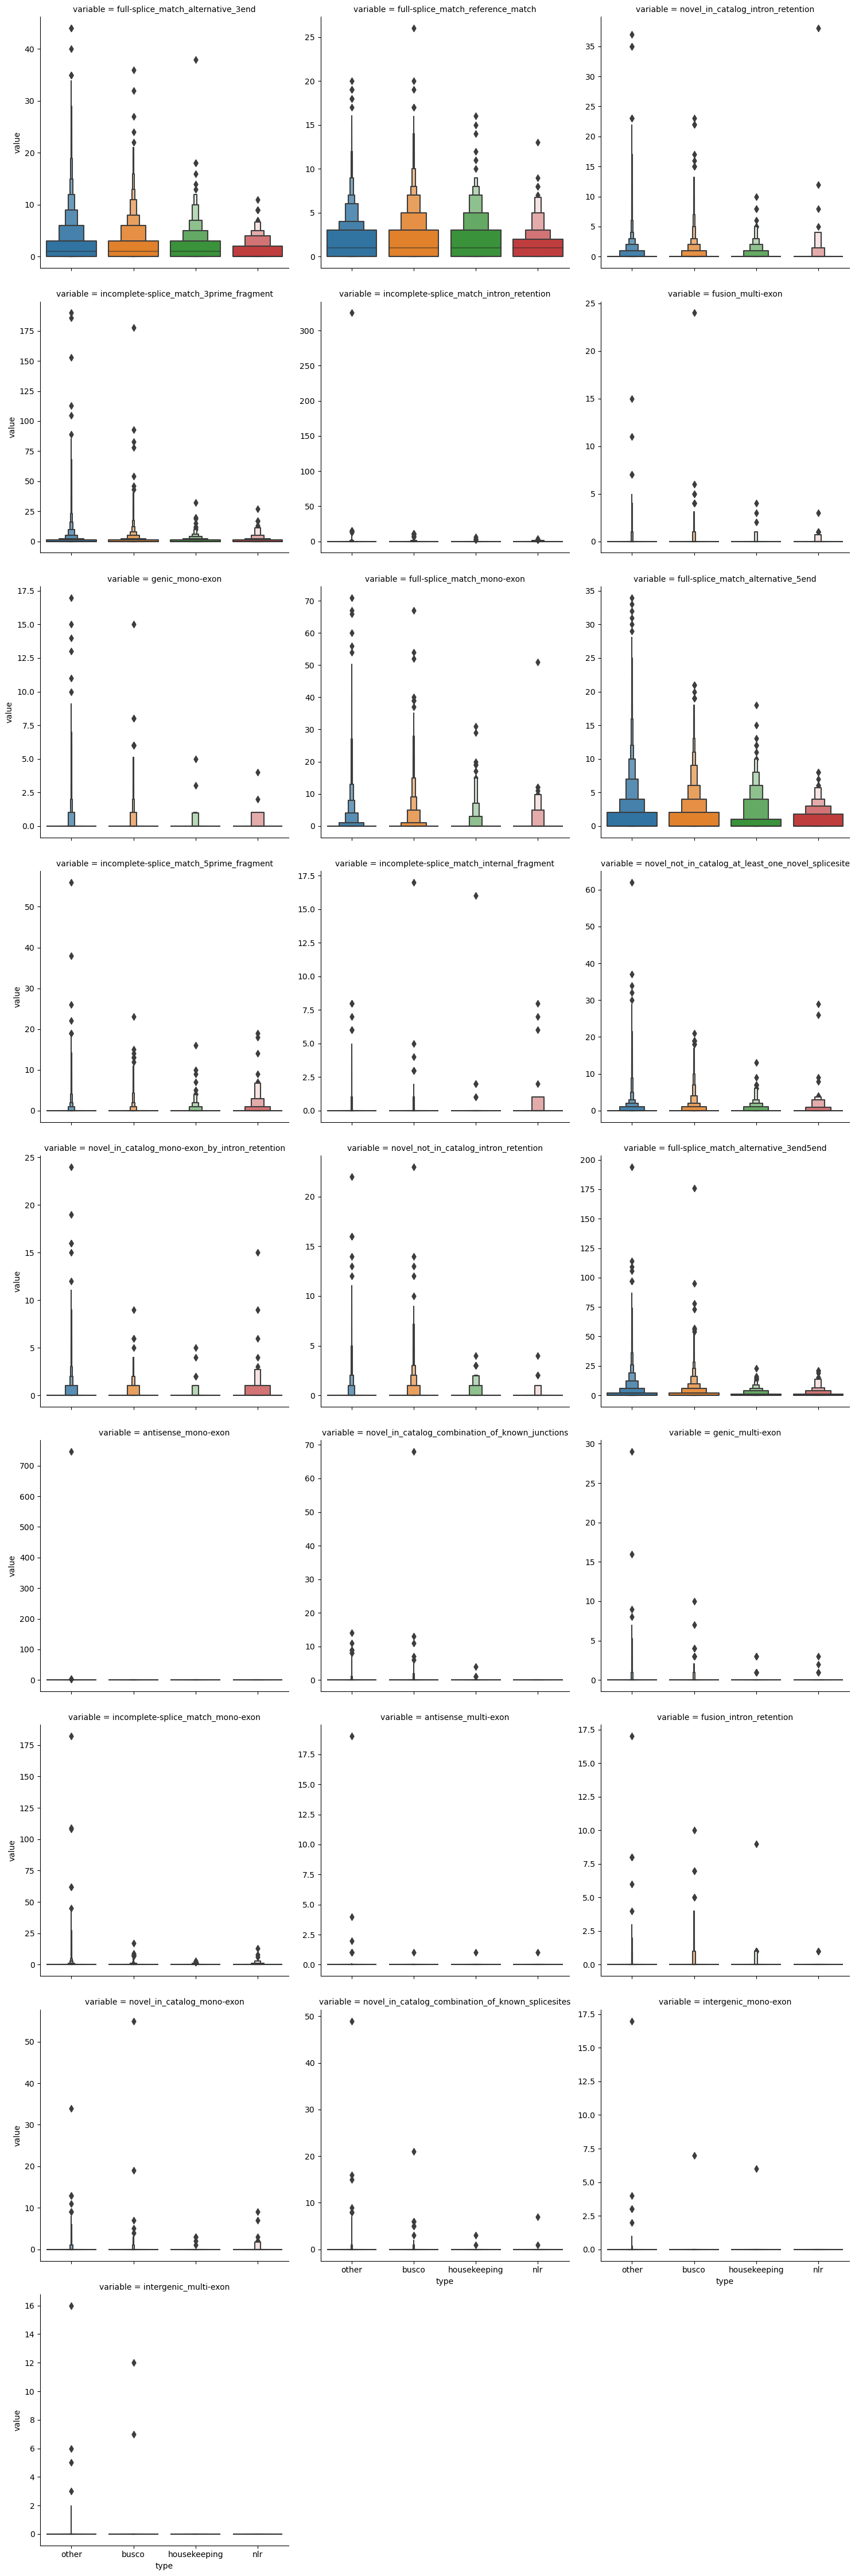

In [115]:
sns.catplot(df_iso, x="type",y="value", kind="boxen", col="variable", sharey=False, col_wrap=3)

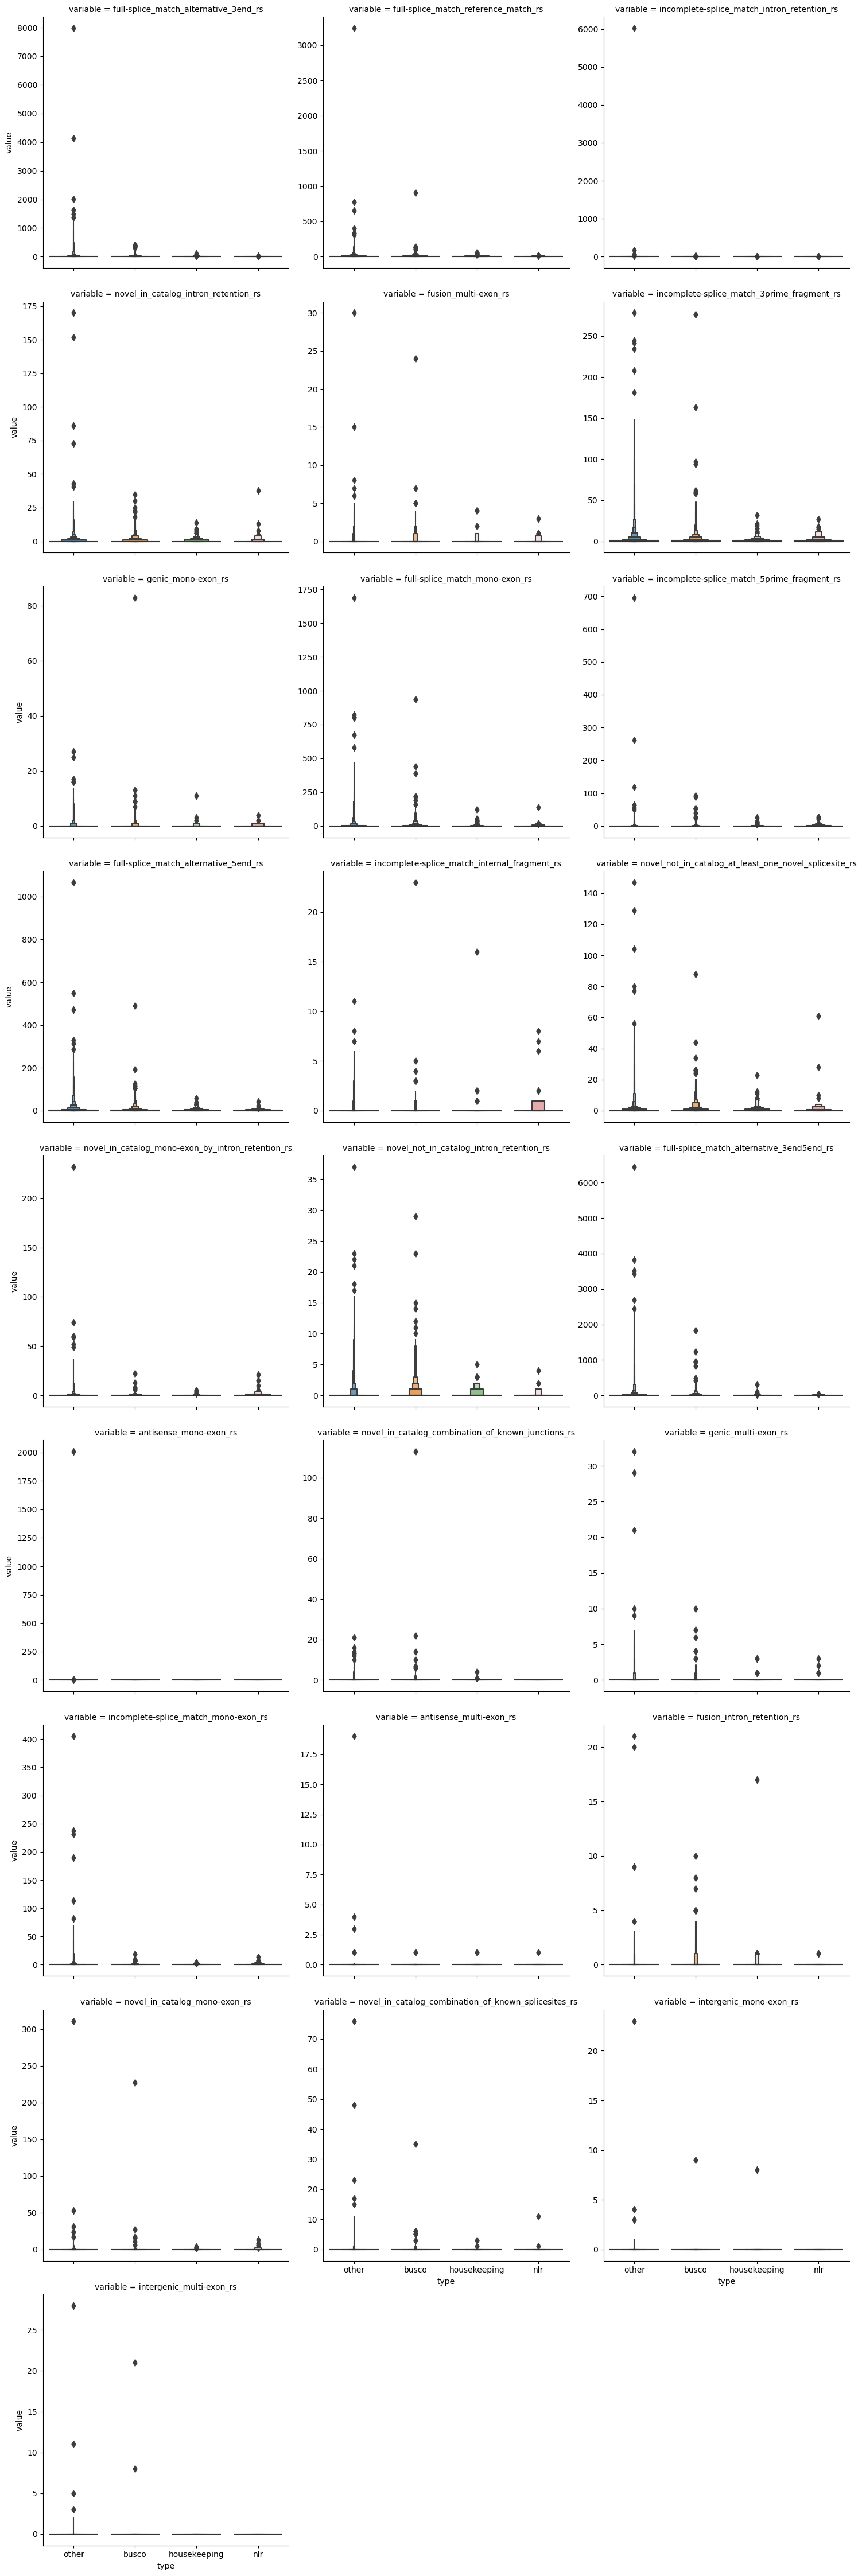

In [116]:
sns.catplot(df_rs, x="type",y="value", kind="boxen", col="variable", sharey=False, col_wrap=3)